# Quantum Transfer Learning for Medical Image Classification (PneumoniaMNIST)

**Question:** when a frozen, pre-trained ResNet-18 supplies the features, does a 4-qubit variational quantum circuit make a better classification head than classical heads?

**Pipeline**
1. Preprocess PneumoniaMNIST chest X-rays (grayscale → 3-channel, 224×224, ImageNet normalisation) and extract 512-d features with a **frozen** ResNet-18 (done once and cached).
2. Classical heads: a plain linear layer, and a parameter-matched 512→4→4→2 bottleneck.
3. Hybrid head: `Linear(512→4)` → **4-qubit PennyLane circuit** (AngleEmbedding + variational `Rot`/CNOT layers, ⟨Z⟩ readout) → `Linear(4→2)`, trained end-to-end with PyTorch.
4. Evaluate on the held-out test set (accuracy, AUC, F1, sensitivity, specificity, confusion matrix, ROC), then run two experiments: a **multi-seed comparison** and a **circuit-depth sweep**.

**Evaluation protocol:** official train/val/test splits; the best epoch is chosen by *validation* loss only; the test set is used once per trained model for reporting. Pneumonia is the positive class (62.5 % of the test set), so we report **AUC, sensitivity and specificity** alongside accuracy.

In [1]:
!pip install pennylane torch torchvision matplotlib scikit-learn
!pip install medmnist


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import (roc_auc_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, classification_report)

def set_seed(s):
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

set_seed(42)

## 1. Data and frozen feature extraction
PneumoniaMNIST (28×28 grayscale, binary: Normal vs. Pneumonia). Images are upscaled to 224×224 and fed through ResNet-18 with its classifier removed; the resulting 512-d vectors are cached in `raw_features.pt`, so every head below trains in seconds-to-minutes without re-running the CNN. Features are then standardised using **training-set** statistics only. The training set is imbalanced (≈74 % pneumonia), so the loss is class-weighted.

In [3]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from medmnist import PneumoniaMNIST

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Transform grayscale (1 channel) to 3-channel RGB and resize for ResNet-18
data_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Download and load official PneumoniaMNIST splits
train_raw = PneumoniaMNIST(split='train', transform=data_transform, download=True)
val_raw   = PneumoniaMNIST(split='val',   transform=data_transform, download=True)
test_raw  = PneumoniaMNIST(split='test',  transform=data_transform, download=True)

print(f"Dataset loaded: {len(train_raw)} train, {len(val_raw)} val, {len(test_raw)} test images.")

Dataset loaded: 4708 train, 524 val, 624 test images.


In [4]:
from torchvision import models
import torch.nn as nn
from tqdm import tqdm

resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
feature_extractor = nn.Sequential(*list(resnet.children())[:-1]).to(device)
feature_extractor.eval()

def extract_features(dataset, batch_size=64):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    feats_all, labels_all = [], []
    with torch.no_grad():
        for imgs, lbls in tqdm(loader, desc="Extracting"):
            f = feature_extractor(imgs.to(device))
            feats_all.append(torch.flatten(f, 1).cpu()) # dim -> (B, 512)
            labels_all.append(lbls.view(-1).long()) # dim -> (B,)
    return torch.cat(feats_all), torch.cat(labels_all)

X_train, y_train = extract_features(train_raw)
X_val,   y_val   = extract_features(val_raw)
X_test,  y_test  = extract_features(test_raw)

torch.save({'X_train': X_train, 'y_train': y_train, 'X_val': X_val, 'y_val': y_val,
            'X_test': X_test, 'y_test': y_test}, 'raw_features.pt')
print(X_train.shape, X_val.shape, X_test.shape)

Extracting: 100%|██████████| 10/10 [00:27<00:00,  2.71s/it]

torch.Size([4708, 512]) torch.Size([524, 512]) torch.Size([624, 512])


In [5]:
mu, sd = X_train.mean(0), X_train.std(0) + 1e-6
X_train, X_val, X_test = [(X - mu) / sd for X in (X_train, X_val, X_test)]

def make_loaders(Xtr, ytr, bs=32):
    return {
        'train': DataLoader(TensorDataset(Xtr, ytr), batch_size=bs, shuffle=True),
        'val':   DataLoader(TensorDataset(X_val, y_val), batch_size=bs, shuffle=False),
        'test':  DataLoader(TensorDataset(X_test, y_test), batch_size=bs, shuffle=False),
    }

def get_class_weights(y):
    counts = torch.bincount(y)
    return (counts.sum() / (2.0 * counts)).float().to(device) # weight classes acc to frequency

dataloaders = make_loaders(X_train, y_train)
test_loader = dataloaders['test']
class_w = get_class_weights(y_train)

print("Train class counts:", torch.bincount(y_train).tolist())
print("Test class counts: ", torch.bincount(y_test).tolist())
print("Class weights:", class_w.tolist())

Train class counts: [1214, 3494]
Test class counts:  [234, 390]
Class weights: [1.93904447555542, 0.6737263798713684]


## 2. Training and evaluation routine
One shared loop is used for **all** models (Adam, class-weighted cross-entropy, best-validation-loss checkpoint) so comparisons are fair. Besides losses and AUC it logs the mean gradient norm per epoch, and separately the gradient norm of the **quantum circuit weights** (a barren-plateau / trainability diagnostic).

In [6]:
import torch.optim as optim
import copy

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def train_and_evaluate(model, dataloaders, epochs=30, lr=5e-3, class_weights=None, name="Model", verbose=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    opt = optim.Adam(model.parameters(), lr=lr)
    best_loss, best_w = float('inf'), copy.deepcopy(model.state_dict())
    hist = {'train_loss': [], 'val_loss': [], 'val_auc': [], 'val_f1': [], 'grad_norm': [], 'q_grad_norm': []}

    for ep in range(epochs):
        # training phase
        model.train()
        tl, n, gn, qgn, nb, correct = 0.0, 0, 0.0, 0.0, 0, 0
        for x, y in dataloaders['train']:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            grads = [p.grad.norm() for p in model.parameters() if p.grad is not None]
            gn += torch.norm(torch.stack(grads)).item()
            # gradient norm of the quantum circuit weights only (barren-plateau diagnostic)
            qg = [p.grad.norm() for k, p in model.named_parameters() if k.startswith('qlayer') and p.grad is not None]
            qgn += torch.norm(torch.stack(qg)).item() if qg else float('nan')
            nb += 1
            opt.step()
            tl += loss.item() * len(y)
            n += len(y)
            correct += (out.argmax(1) == y).sum().item()
        train_acc = correct / n

        # validation phase
        model.eval()
        vl, vn, vcorrect, probs, labs = 0.0, 0, 0, [], []
        with torch.no_grad():
            for x, y in dataloaders['val']:
                out = model(x.to(device))
                vl += criterion(out, y.to(device)).item() * len(y)
                vn += len(y)
                vcorrect += (out.argmax(1).cpu() == y).sum().item()
                probs.append(torch.softmax(out, 1)[:, 1].cpu())
                labs.append(y)
        probs = torch.cat(probs).numpy()
        labs = torch.cat(labs).numpy()
        val_loss = vl / vn
        val_acc = vcorrect / vn
        auc = roc_auc_score(labs, probs)
        f1 = f1_score(labs, (probs > 0.5).astype(int), average='macro')

        hist['train_loss'].append(tl / n)
        hist['val_loss'].append(val_loss)
        hist['val_auc'].append(auc)
        hist['val_f1'].append(f1)
        hist['grad_norm'].append(gn / nb)
        hist['q_grad_norm'].append(qgn / nb)

        # checkpoint rule: lowest validation loss (the test set is never used for model selection)
        saved = ""
        if val_loss < best_loss:
            best_loss, best_w = val_loss, copy.deepcopy(model.state_dict())
            saved = " *best"

        if verbose:
            print(f"[{name}] Epoch {ep+1:02d}/{epochs} | "
                  f"train loss {tl/n:.4f} acc {train_acc:.4f} | "
                  f"val loss {val_loss:.4f} acc {val_acc:.4f} auc {auc:.4f} f1 {f1:.4f} | "
                  f"grad {gn/nb:.3f}{saved}")

    model.load_state_dict(best_w)
    if verbose:
        print(f"[{name}] Restored best weights (val loss {best_loss:.4f})")
    return model, hist

## 3. Classical baselines
- **Linear head**: `Linear(512→2)`, the standard transfer-learning head.
- **Classical bottleneck**: `512→4→4→2` with tanh. It has the same 4-wide bottleneck as the hybrid model, with the quantum circuit replaced by a classical 4→4 layer, so any gap to the hybrid model is attributable to the circuit rather than to the compression.

In [7]:
class LinearHead(nn.Module):
    """Plain classical head: a single linear layer on all 512 ResNet features."""
    def __init__(self, in_features=512, num_classes=2):
        super().__init__()
        self.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.fc(x)

class BottleneckClassicalClassifier(nn.Module):
    """Parameter-matched control: same 512->4 compression and 4-wide middle as the hybrid model,
    but the quantum circuit is replaced by a classical 4->4 layer."""
    def __init__(self, in_features=512, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 4),
            nn.Tanh(),
            nn.Linear(4, 4),      # classical stand-in for the quantum circuit
            nn.Tanh(),
            nn.Linear(4, num_classes)
        )

    def forward(self, x):
        return self.net(x)

set_seed(42)
linear_model = LinearHead().to(device)
print("Training Classical Linear Head...")
linear_model, linear_history = train_and_evaluate(linear_model, dataloaders, epochs=15, lr=5e-3, class_weights=class_w, name="Linear")

set_seed(42)
classical_model = BottleneckClassicalClassifier().to(device)
print("\nTraining Classical Bottleneck Baseline...")
classical_model, classical_history = train_and_evaluate(classical_model, dataloaders, epochs=15, lr=5e-3, class_weights=class_w, name="Bottleneck")

Training Classical Linear Head...
[Linear] Epoch 01/15 | train loss 0.2295 acc 0.8915 | val loss 0.2063 acc 0.9237 auc 0.9753 f1 0.9058 | grad 1.489 *best
[Linear] Epoch 02/15 | train loss 0.1481 acc 0.9403 | val loss 0.2105 acc 0.9466 auc 0.9727 f1 0.9318 | grad 1.220
[Linear] Epoch 03/15 | train loss 0.1524 acc 0.9352 | val loss 0.1961 acc 0.9447 auc 0.9796 f1 0.9301 | grad 1.203 *best
[Linear] Epoch 04/15 | train loss 0.1236 acc 0.9499 | val loss 0.1611 acc 0.9408 auc 0.9868 f1 0.9256 | grad 1.086 *best
[Linear] Epoch 05/15 | train loss 0.1140 acc 0.9541 | val loss 0.1806 acc 0.9466 auc 0.9854 f1 0.9318 | grad 1.030
[Linear] Epoch 06/15 | train loss 0.1047 acc 0.9584 | val loss 0.2323 acc 0.9466 auc 0.9747 f1 0.9302 | grad 1.012
[Linear] Epoch 07/15 | train loss 0.1099 acc 0.9569 | val loss 0.1902 acc 0.9427 auc 0.9828 f1 0.9252 | grad 1.002
[Linear] Epoch 08/15 | train loss 0.0995 acc 0.9588 | val loss 0.1745 acc 0.9561 auc 0.9874 f1 0.9422 | grad 0.942
[Linear] Epoch 09/15 | train

## 4. Hybrid quantum classifier
`Linear(512→4)` + tanh (scaled to [−π/2, π/2]) → angle-embed into 4 qubits → `q_depth` × (`Rot` on each qubit, then a ring of CNOTs) → ⟨Z⟩ on each qubit → `Linear(4→2)`. The circuit has `q_depth × 4 × 3` trainable parameters and is simulated exactly (`default.qubit`, backprop). `q_depth` and an `entangle` switch are arguments so the depth sweep and the no-entanglement ablation reuse the same class.

In [8]:
import pennylane as qml
import numpy as np
import torch
import torch.nn as nn

n_qubits = 4
dev = qml.device("default.qubit", wires=n_qubits)

def make_qnode(q_depth=2, entangle=True):
    """Variational circuit: AngleEmbedding -> q_depth x (Rot on every qubit + ring of CNOTs) -> <Z> on every qubit."""
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        # AngleEmbedding natively supports batched inputs (batch_size, n_qubits)
        qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")

        # Variational layers: single-qubit rotations followed by entangling CNOTs
        for l in range(q_depth):
            for i in range(n_qubits):
                qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)
            if entangle:  # entangle=False is used as an ablation
                for i in range(n_qubits):
                    qml.CNOT(wires=[i, (i + 1) % n_qubits])

        # Measure Pauli-Z expectation values across all 4 qubits
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]
    return circuit

class HybridQuantumClassifier(nn.Module):
    def __init__(self, in_features=512, num_classes=2, q_depth=2, entangle=True):
        super().__init__()
        self.pre_net = nn.Sequential(
            nn.Linear(in_features, n_qubits),
            nn.Tanh()
        )
        self.qlayer = qml.qnn.TorchLayer(make_qnode(q_depth, entangle), {"weights": (q_depth, n_qubits, 3)})
        self.post_net = nn.Linear(n_qubits, num_classes)

    def forward(self, x):
        # Scale tanh outputs into [-pi/2, pi/2]
        x = self.pre_net(x) * (np.pi / 2.0)

        # TorchLayer automatically broadcasts over batch dimension
        x = self.qlayer(x)

        # Ensure tensor matches post_net's device and dtype
        x = x.to(device=self.post_net.weight.device, dtype=torch.float32)
        x = self.post_net(x)
        return x

# Standard ASCII diagram of the depth-2 circuit (dummy inputs/weights, only the structure matters)
print(qml.draw(make_qnode(2))(torch.zeros(4), torch.zeros((2, n_qubits, 3))))

set_seed(42)
hybrid_model = HybridQuantumClassifier(q_depth=2).to(device)
print("\nTraining Hybrid Quantum Model...")
hybrid_model, quantum_history = train_and_evaluate(hybrid_model, dataloaders, epochs=15, lr=5e-3, class_weights=class_w, name="Hybrid")

0: ─╭AngleEmbedding(M0)──Rot(0.00,0.00,0.00)─╭●───────╭X──Rot(0.00,0.00,0.00)─╭●───────╭X─┤  <Z>
1: ─├AngleEmbedding(M0)──Rot(0.00,0.00,0.00)─╰X─╭●────│───Rot(0.00,0.00,0.00)─╰X─╭●────│──┤  <Z>
2: ─├AngleEmbedding(M0)──Rot(0.00,0.00,0.00)────╰X─╭●─│───Rot(0.00,0.00,0.00)────╰X─╭●─│──┤  <Z>
3: ─╰AngleEmbedding(M0)──Rot(0.00,0.00,0.00)───────╰X─╰●──Rot(0.00,0.00,0.00)───────╰X─╰●─┤  <Z>

M0 = 
tensor([0., 0., 0., 0.])

Training Hybrid Quantum Model...
[Hybrid] Epoch 01/15 | train loss 0.4296 acc 0.8583 | val loss 0.3484 acc 0.8607 auc 0.9130 f1 0.8361 | grad 1.051 *best
[Hybrid] Epoch 02/15 | train loss 0.2572 acc 0.9131 | val loss 0.2705 acc 0.8969 auc 0.9447 f1 0.8763 | grad 1.219 *best
[Hybrid] Epoch 03/15 | train loss 0.2064 acc 0.9240 | val loss 0.2019 acc 0.9198 auc 0.9725 f1 0.9015 | grad 0.989 *best
[Hybrid] Epoch 04/15 | train loss 0.1759 acc 0.9346 | val loss 0.2442 acc 0.9218 auc 0.9655 f1 0.9003 | grad 0.851
[Hybrid] Epoch 05/15 | train loss 0.1493 acc 0.9454 | val loss 0.202

## 5. Test-set evaluation (single run, seed 42)
Summary table, per-model classification reports, confusion matrices and ROC curves, followed by training curves. A single run is only a first look: differences this small are comparable to seed-to-seed noise, which Experiment 1 quantifies.


Linear head  |  AUC = 0.9437
              precision    recall  f1-score   support

      Normal       0.91      0.76      0.83       234
   Pneumonia       0.87      0.96      0.91       390

    accuracy                           0.88       624
   macro avg       0.89      0.86      0.87       624
weighted avg       0.88      0.88      0.88       624


Classical bottleneck  |  AUC = 0.9489
              precision    recall  f1-score   support

      Normal       0.92      0.72      0.81       234
   Pneumonia       0.85      0.96      0.90       390

    accuracy                           0.87       624
   macro avg       0.89      0.84      0.86       624
weighted avg       0.88      0.87      0.87       624


Hybrid quantum (L=2)  |  AUC = 0.9285
              precision    recall  f1-score   support

      Normal       0.91      0.70      0.79       234
   Pneumonia       0.84      0.96      0.89       390

    accuracy                           0.86       624
   macro avg       0

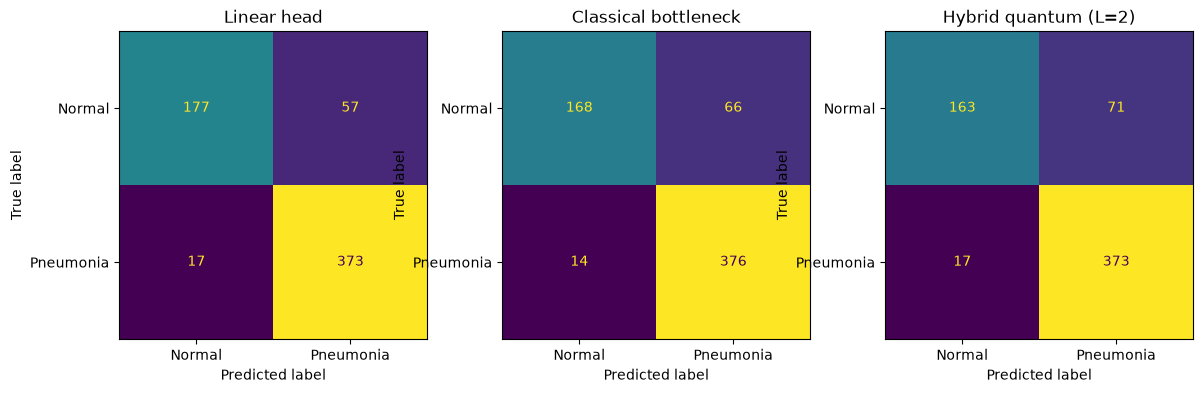

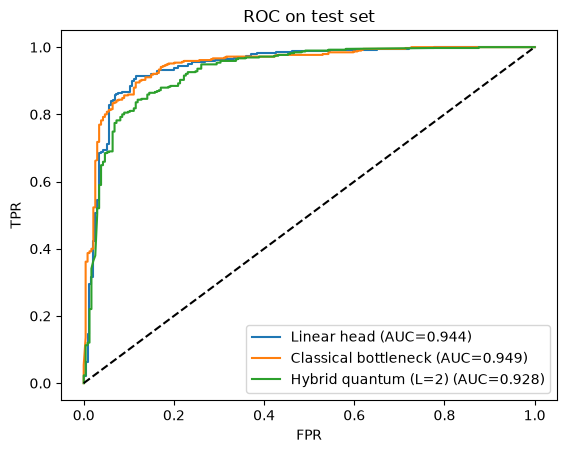

In [9]:
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, classification_report
import matplotlib.pyplot as plt

def evaluate(model, loader):
    model.eval()
    labels, preds, probs = [], [], []
    with torch.no_grad():
        for x,y in loader:
            out = model(x.to(device)) # shape: (B, 2) -> holds raw scores for each class
            probs.append(torch.softmax(out, 1)[:, 1].cpu()) # performs softmax on raw logits and gets probability score for pneumonia after taking col 1
            preds.append(out.argmax(1).cpu())
            labels.append(y)

    return (torch.cat(labels).numpy(), torch.cat(preds).numpy(), torch.cat(probs).numpy())

def test_metrics(model):
    """Test-set metrics. Pneumonia = positive class, so sensitivity = recall on pneumonia."""
    yt, yp, yprob = evaluate(model, test_loader)
    tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    return dict(acc=(tp + tn) / len(yt), auc=roc_auc_score(yt, yprob),
                f1=f1_score(yt, yp, average='macro'), sens=tp / (tp + fn), spec=tn / (tn + fp))

models = [("Linear head", linear_model), ("Classical bottleneck", classical_model), ("Hybrid quantum (L=2)", hybrid_model)]

results, rows = {}, []
for name, model in models:
    y_true, y_pred, y_prob = evaluate(model, test_loader)
    results[name] = (y_true, y_pred, y_prob)
    rows.append({"model": name, "params": count_params(model), **test_metrics(model)})
    print(f"\n{name}  |  AUC = {roc_auc_score(y_true, y_prob):.4f}")
    print(classification_report(y_true, y_pred, target_names=["Normal", "Pneumonia"]))

print("Test-set summary (single run, seed 42):")
print(pd.DataFrame(rows).set_index("model").round(4).to_string())

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, (yt, yp, _)) in zip(axes, results.items()):
    ConfusionMatrixDisplay(confusion_matrix(yt, yp),
                           display_labels=["Normal", "Pneumonia"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

# ROC curves
for name, (yt, _, yprob) in results.items():
    fpr, tpr, _ = roc_curve(yt, yprob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yt, yprob):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.legend(); plt.title("ROC on test set"); plt.show()

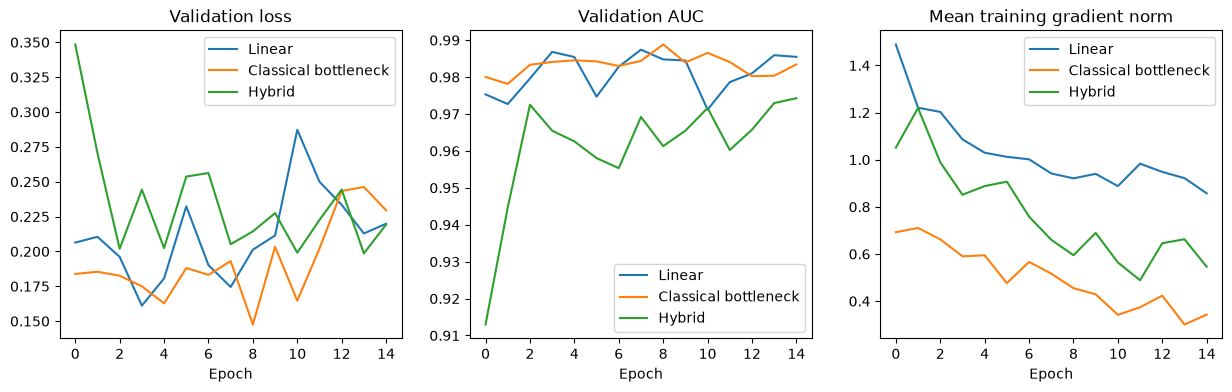

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, h in [("Linear", linear_history), ("Classical bottleneck", classical_history), ("Hybrid", quantum_history)]:
    axes[0].plot(h['val_loss'], label=name)
    axes[1].plot(h['val_auc'], label=name)
    axes[2].plot(h['grad_norm'], label=name)
axes[0].set_title("Validation loss")
axes[1].set_title("Validation AUC")
axes[2].set_title("Mean training gradient norm")
for a in axes:
    a.set_xlabel("Epoch")
    a.legend()
plt.show()

## 6. Experiments
All experiments retrain every model from scratch with different random seeds and report **mean ± std**. Edit the configuration cell to trade runtime against precision. "Convergence speed" is the first epoch at which validation AUC reaches `AUC_TARGET`.

In [11]:
# ---- Experiment configuration (reduce SEEDS / DEPTHS / epochs if runtime is a problem) ----
EPOCHS      = 15
LR          = 5e-3
SEEDS       = [0, 1, 2, 3, 4]          # Experiment 1
DEPTHS      = [1, 2, 3, 4, 6]          # Experiment 2
DEPTH_SEEDS = [0, 1, 2]
AUC_TARGET  = 0.97                     # "converged" = first epoch with validation AUC >= this

def run_experiment(make_model, seed, loaders, cw, epochs=EPOCHS):
    """Train one model from scratch with a given seed; return test metrics + diagnostics + history."""
    set_seed(seed)
    m = make_model()
    m, h = train_and_evaluate(m, loaders, epochs=epochs, lr=LR, class_weights=cw, verbose=False)
    r = test_metrics(m)
    hit = [i + 1 for i, a in enumerate(h['val_auc']) if a >= AUC_TARGET]
    r.update(epochs_to_target=hit[0] if hit else np.nan,
             grad_norm=np.mean(h['grad_norm']), q_grad=np.mean(h['q_grad_norm']), params=count_params(m))
    return r, h

def mean_std(df, group, cols):
    """Format 'mean ± std' per group."""
    g = df.groupby(group, sort=False)[cols]
    m, s = g.mean(), g.std()
    return m.map(lambda v: f"{v:.4f}") + " ± " + s.map(lambda v: f"{v:.4f}")

### Experiment 1: head comparison over multiple seeds
Includes a **no-CNOT ablation** of the hybrid model (identical circuit without entanglement) to test whether entanglement contributes. The Welch t-test is only indicative given the small number of seeds.

In [12]:
MODELS = {
    "Linear head":          lambda: LinearHead(),
    "Classical bottleneck": lambda: BottleneckClassicalClassifier(),
    "Hybrid quantum (L=2)": lambda: HybridQuantumClassifier(q_depth=2),
    "Hybrid no-CNOT (L=2)": lambda: HybridQuantumClassifier(q_depth=2, entangle=False),  # ablation
}

records, val_curves = [], {}
for name, mk in MODELS.items():
    for s in SEEDS:
        r, h = run_experiment(mk, s, dataloaders, class_w)
        records.append({"model": name, "seed": s, **r})
        val_curves.setdefault(name, []).append(h['val_loss'])
        print(f"{name:22s} seed {s} | test AUC {r['auc']:.4f} acc {r['acc']:.4f} sens {r['sens']:.4f} spec {r['spec']:.4f}")
df_seeds = pd.DataFrame(records)

cols = ['acc', 'auc', 'f1', 'sens', 'spec']
table = mean_std(df_seeds, 'model', cols)
table['epochs_to_AUC>=%.2f' % AUC_TARGET] = df_seeds.groupby('model', sort=False)['epochs_to_target'].apply(
    lambda v: f"{v.mean():.1f} ({v.notna().sum()}/{len(v)} reached)")
table['params'] = df_seeds.groupby('model', sort=False)['params'].first()
print(f"\nTest metrics, mean ± std over {len(SEEDS)} seeds:")
print(table.to_string())

# Welch t-test on test AUC: hybrid vs. parameter-matched classical bottleneck (indicative only, small n)
from scipy import stats
a = df_seeds[df_seeds.model == "Hybrid quantum (L=2)"].auc
b = df_seeds[df_seeds.model == "Classical bottleneck"].auc
print(f"\nHybrid vs classical bottleneck, test AUC: {a.mean():.4f} vs {b.mean():.4f}, Welch p = {stats.ttest_ind(a, b, equal_var=False).pvalue:.3f}")

Linear head            seed 0 | test AUC 0.9404 acc 0.8766 sens 0.9564 spec 0.7436
Linear head            seed 1 | test AUC 0.9418 acc 0.8766 sens 0.9641 spec 0.7308
Linear head            seed 2 | test AUC 0.9434 acc 0.8814 sens 0.9513 spec 0.7650
Linear head            seed 3 | test AUC 0.9368 acc 0.8766 sens 0.9487 spec 0.7564
Linear head            seed 4 | test AUC 0.9182 acc 0.8622 sens 0.9615 spec 0.6966
Classical bottleneck   seed 0 | test AUC 0.9441 acc 0.8654 sens 0.9385 spec 0.7436
Classical bottleneck   seed 1 | test AUC 0.9326 acc 0.8846 sens 0.9513 spec 0.7735
Classical bottleneck   seed 2 | test AUC 0.9470 acc 0.8606 sens 0.9538 spec 0.7051
Classical bottleneck   seed 3 | test AUC 0.9471 acc 0.8734 sens 0.9487 spec 0.7479
Classical bottleneck   seed 4 | test AUC 0.9445 acc 0.8718 sens 0.9564 spec 0.7308
Hybrid quantum (L=2)   seed 0 | test AUC 0.9325 acc 0.8718 sens 0.9641 spec 0.7179
Hybrid quantum (L=2)   seed 1 | test AUC 0.9358 acc 0.8654 sens 0.9615 spec 0.7051
Hybr

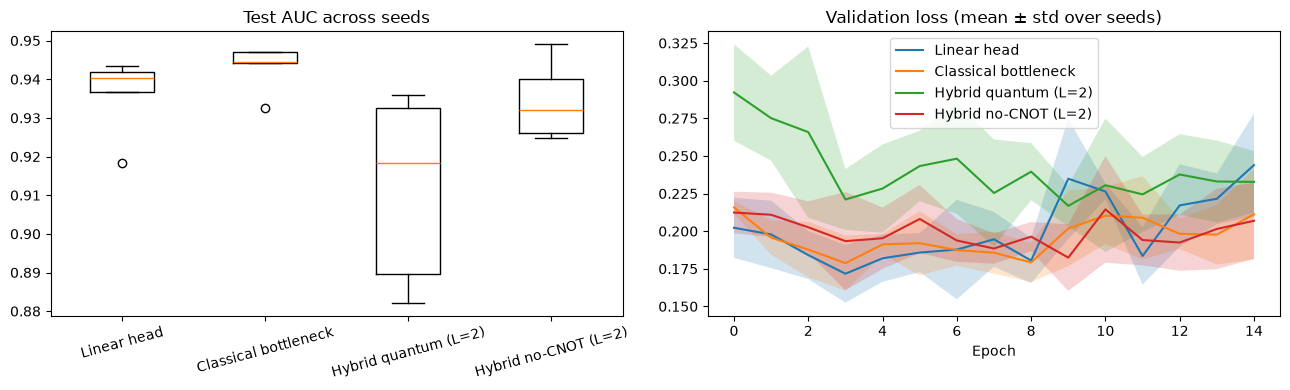

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = list(MODELS)
axes[0].boxplot([df_seeds[df_seeds.model == n].auc for n in names])
axes[0].set_xticks(range(1, len(names) + 1)); axes[0].set_xticklabels(names)
axes[0].set_title("Test AUC across seeds"); axes[0].tick_params(axis='x', rotation=15)
for n in names:
    c = np.array(val_curves[n]); mu_, sd_ = c.mean(0), c.std(0)
    axes[1].plot(mu_, label=n); axes[1].fill_between(range(len(mu_)), mu_ - sd_, mu_ + sd_, alpha=0.2)
axes[1].set_title("Validation loss (mean ± std over seeds)"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

### Experiment 2: circuit depth, accuracy and trainability
Sweeps the number of variational layers. If gradients of the quantum weights shrink quickly with depth, that is the signature of barren plateaus; with 4 qubits it is expected to be mild, but it is the relevant trend for scaling up.

depth 1 seed 0 | test AUC 0.9098 | quantum-weight grad norm 0.1085 | epochs to target 13
depth 1 seed 1 | test AUC 0.8811 | quantum-weight grad norm 0.0778 | epochs to target nan
depth 1 seed 2 | test AUC 0.8991 | quantum-weight grad norm 0.0906 | epochs to target nan
depth 2 seed 0 | test AUC 0.9325 | quantum-weight grad norm 0.1086 | epochs to target 5
depth 2 seed 1 | test AUC 0.9358 | quantum-weight grad norm 0.0830 | epochs to target 4
depth 2 seed 2 | test AUC 0.8822 | quantum-weight grad norm 0.1253 | epochs to target nan
depth 3 seed 0 | test AUC 0.9363 | quantum-weight grad norm 0.1061 | epochs to target 3
depth 3 seed 1 | test AUC 0.9331 | quantum-weight grad norm 0.1355 | epochs to target 2
depth 3 seed 2 | test AUC 0.9273 | quantum-weight grad norm 0.1379 | epochs to target 3
depth 4 seed 0 | test AUC 0.9356 | quantum-weight grad norm 0.1274 | epochs to target 3
depth 4 seed 1 | test AUC 0.9420 | quantum-weight grad norm 0.1325 | epochs to target 5
depth 4 seed 2 | test AUC

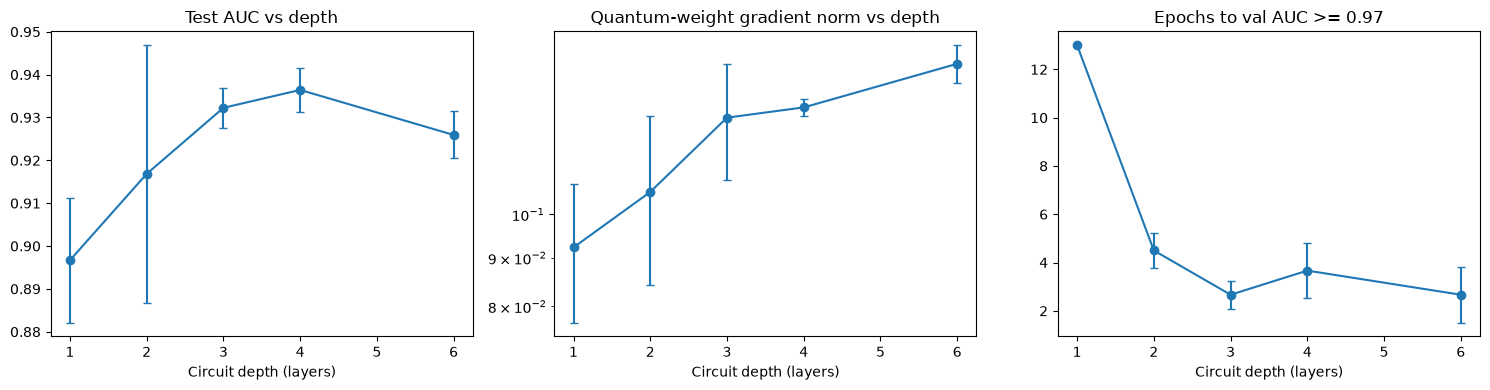

In [14]:
depth_records = []
for L in DEPTHS:
    for s in DEPTH_SEEDS:
        r, _ = run_experiment(lambda: HybridQuantumClassifier(q_depth=L), s, dataloaders, class_w)
        depth_records.append({"depth": L, "seed": s, **r})
        print(f"depth {L} seed {s} | test AUC {r['auc']:.4f} | quantum-weight grad norm {r['q_grad']:.4f} | epochs to target {r['epochs_to_target']}")
df_depth = pd.DataFrame(depth_records)

print("\nPer-depth summary (mean over seeds):")
print(df_depth.groupby('depth')[['auc', 'acc', 'q_grad', 'epochs_to_target', 'params']].mean().round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
g = df_depth.groupby('depth')
for ax, col, title in zip(axes, ['auc', 'q_grad', 'epochs_to_target'],
                          ['Test AUC vs depth', 'Quantum-weight gradient norm vs depth', f'Epochs to val AUC >= {AUC_TARGET}']):
    ax.errorbar(g[col].mean().index, g[col].mean(), yerr=g[col].std(), marker='o', capsize=3)
    ax.set_title(title); ax.set_xlabel("Circuit depth (layers)")
axes[1].set_yscale('log')
plt.tight_layout(); plt.show()

## 7. Discussion and limitations

**Findings** (test set, mean ± std; Exp. 1 over 5 seeds, Exp. 2 over 3 seeds)

- **Head comparison (Exp. 1).** The classical heads are at least as good as the quantum head. Test AUC: classical bottleneck **0.943 ± 0.006**, linear head **0.936 ± 0.010**, hybrid quantum (L=2) **0.912 ± 0.025**. The hybrid vs. parameter-matched bottleneck gap is statistically detectable (Welch p = 0.044) but only with 5 seeds, so treat it as suggestive. The hybrid is also the least stable run to run (std 0.025 vs 0.006). All models reach very high sensitivity (≈0.95–0.96) at the cost of lower specificity (≈0.67–0.74), which is expected given the 74 % pneumonia training set and the 62.5 % pneumonia test set.
- **Convergence speed.** Classical heads reach validation AUC ≥ 0.97 in 1–2 epochs. The L=2 hybrid needs about 5 epochs and failed to reach the target within 15 epochs in 2 of 5 seeds. In this setting the quantum head trains slower and less reliably.
- **Entanglement ablation.** Removing the CNOTs *improved* the L=2 hybrid (AUC 0.934 ± 0.010, all seeds converge), matching the classical heads. With only 2 layers on 4 qubits, entanglement did not help and probably made optimisation harder, so we cannot claim entanglement contributes here.
- **Depth (Exp. 2).** Test AUC rises from 0.897 (L=1) to 0.917 (L=2) and ≈0.93 for L=3–6 (peak 0.936 at L=4, then flat or slightly lower at L=6). Convergence speeds up with depth (first epoch to reach val AUC ≥ 0.97: 13 for L=1, which only 1 of 3 seeds reached, versus ≈3 for L≥3). Deeper circuits close the gap to the classical heads but do not surpass them. **No barren plateau was observed:** the gradient norm of the quantum weights *increases* slightly with depth (0.092 → 0.144). This is expected for 4 qubits and says nothing about scalability to larger circuits.

**Overall conclusion.** A 4-qubit variational head on frozen ResNet-18 features is *trainable* and reaches clinically-plausible AUC (~0.91–0.94), and deeper circuits help up to about 3–4 layers, but it does not beat equally sized classical heads in accuracy, stability or convergence speed. This is an honest negative/neutral result, not evidence of quantum advantage.

**Limitations**
- **Simulation only.** Training uses a noiseless state-vector simulator with backprop; real hardware would need parameter-shift gradients (many more circuit evaluations), shot noise and gate noise.
- **The classical front end does the heavy lifting.** Frozen ResNet-18 features are already highly separable (≈0.98 AUC on validation, ≈0.94 on test for a linear head; the val/test gap reflects the official split's distribution shift), so there is little headroom for any head. Most of the remaining error is specificity, not something a small head can fix.
- **Tiny circuit and bottleneck.** Only 4 qubits and a 512→4 compression: information is lost before the circuit, and a 4-qubit circuit is easy to simulate classically, so no quantum advantage should be claimed.
- **Low resolution data.** PneumoniaMNIST images are 28×28 upscaled to 224×224, far from clinical imaging conditions; results do not imply clinical utility.
- **Statistics.** 3–5 seeds give rough error bars; the test set has 624 images; p-values are indicative only and no multiple-comparison correction was applied.
- **Model selection and tuning.** Checkpoints are chosen on a fixed validation set, and hyper-parameters (learning rate 5e-3, 15 epochs) were not tuned per model; the quantum head may benefit from a different learning rate or more epochs, which we did not test. Epochs-to-target averages only over seeds that reached the target.